# Non-AI Screw Counter — Screws_2024_07_15

**Dataset:** 6 images of golden flat-head screws on a white background

**Approach:** Pure OpenCV — no machine learning involved

**Pipeline:**
1. Convert to grayscale
2. Gaussian blur to smooth out minor noise
3. Otsu thresholding (inverted) — screws become white foreground, background becomes black
4. Morphological close → fills small holes inside screw shapes
5. Morphological open → removes tiny speckle noise
6. `findContours` to detect object boundaries
7. Filter contours by area (400–15000 px²) to discard background artifacts and merged blobs
8. Count remaining contours = count of screws

**Why this works:** Screws are dark objects on a uniform white background, so Otsu thresholding cleanly separates them. The area filter handles edge cases where two touching screws might partially merge.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from pathlib import Path

DATA_DIR = Path(r'C:\Users\ACER\Downloads\Screws_2024_07_15-20261104T141212Z-1-001\Screws_2024_07_15')

image_files = sorted([f for f in DATA_DIR.glob('*.jpg') if 'nosy' not in f.name])
print('Images found:', [f.name for f in image_files])

Images found: ['img1.jpg', 'img2.jpg', 'img3.jpg', 'img4.jpg', 'img5.jpg', 'img6.jpg']


In [3]:
def count_screws(image_path, min_area=400, max_area=15000, debug=False):
    """
    Count screws using contour detection.
    Returns: (count, overlay_image, contours)
    """
    img = cv2.imread(str(image_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Gaussian blur to reduce noise
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Otsu thresholding - inverts so screws = white foreground
    _, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Morphological close: fills holes in screws
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    cleaned = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=2)
    # Morphological open: removes tiny noise
    cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_OPEN, kernel, iterations=1)

    # Find contours
    contours, _ = cv2.findContours(cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Filter by area
    valid_contours = [c for c in contours if min_area < cv2.contourArea(c) < max_area]

    # Build colored overlay
    overlay = img_rgb.copy()
    mask_layer = np.zeros_like(img_rgb)
    np.random.seed(42)
    for i, cnt in enumerate(valid_contours):
        color = tuple(np.random.randint(50, 255, 3).tolist())
        cv2.drawContours(mask_layer, [cnt], -1, color, thickness=cv2.FILLED)
        # Draw bounding box
        x, y, w, h = cv2.boundingRect(cnt)
        cv2.rectangle(overlay, (x, y), (x+w, y+h), (255, 0, 0), 2)
        # Label each screw
        cx = x + w // 2
        cy = y + h // 2
        cv2.putText(overlay, str(i+1), (cx-8, cy+5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 1)

    # Blend mask onto image
    overlay = cv2.addWeighted(overlay, 0.7, mask_layer, 0.3, 0)

    # Count label on image
    cv2.putText(overlay, f'Count: {len(valid_contours)}', (20, 50),
                cv2.FONT_HERSHEY_SIMPLEX, 1.5, (220, 20, 20), 3)

    if debug:
        return len(valid_contours), overlay, valid_contours, thresh, cleaned
    return len(valid_contours), overlay, valid_contours

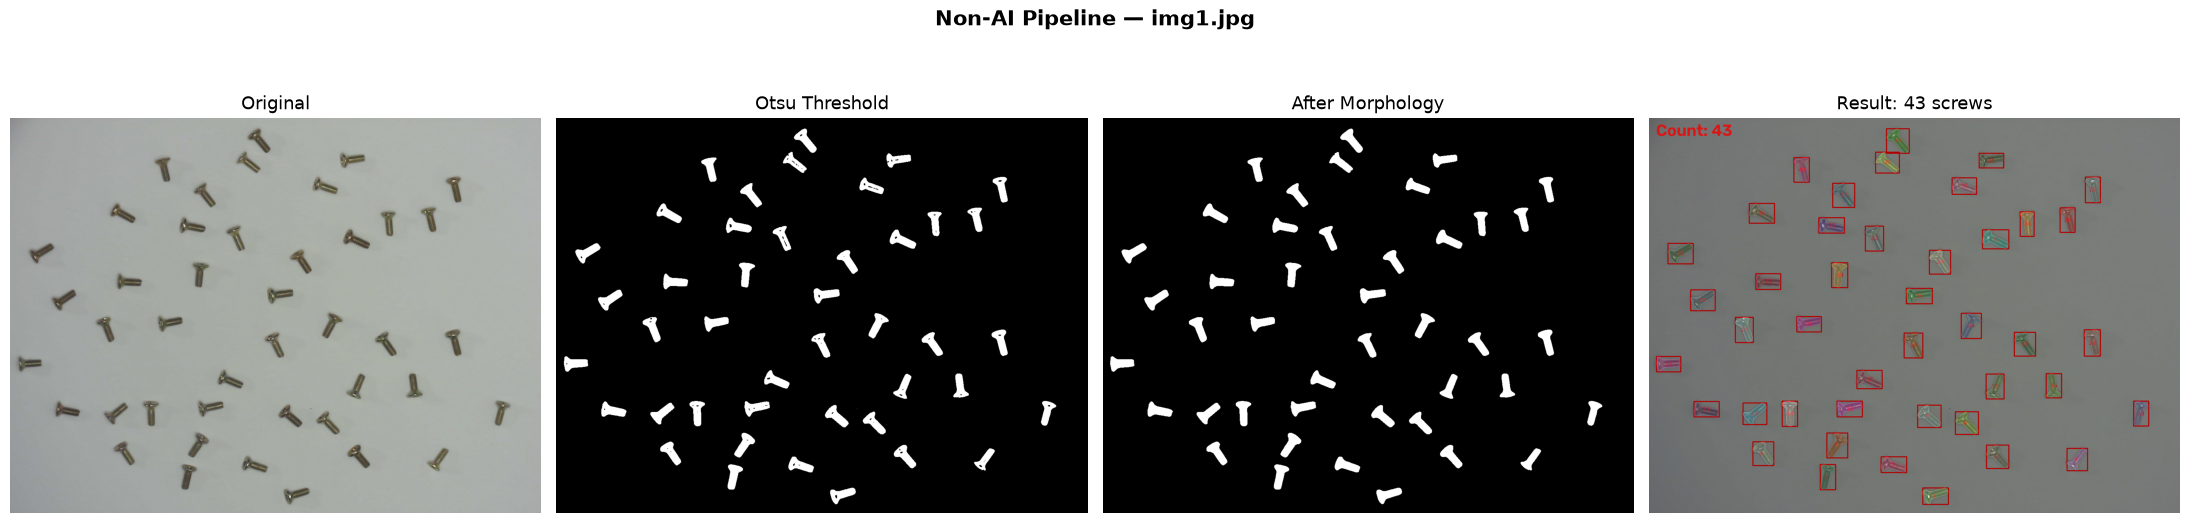

img1.jpg → Detected: 43 screws


In [4]:
# --- Debug pipeline visualization for img1 ---
img_path = DATA_DIR / 'img1.jpg'
count, overlay, contours, thresh, cleaned = count_screws(img_path, debug=True)

img_rgb = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 4, figsize=(22, 6))
axes[0].imshow(img_rgb);            axes[0].set_title('Original', fontsize=13)
axes[1].imshow(thresh, cmap='gray'); axes[1].set_title('Otsu Threshold', fontsize=13)
axes[2].imshow(cleaned, cmap='gray');axes[2].set_title('After Morphology', fontsize=13)
axes[3].imshow(overlay);            axes[3].set_title(f'Result: {count} screws', fontsize=13)
for ax in axes: ax.axis('off')
plt.suptitle('Non-AI Pipeline — img1.jpg', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('pipeline_debug_img1.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'img1.jpg → Detected: {count} screws')

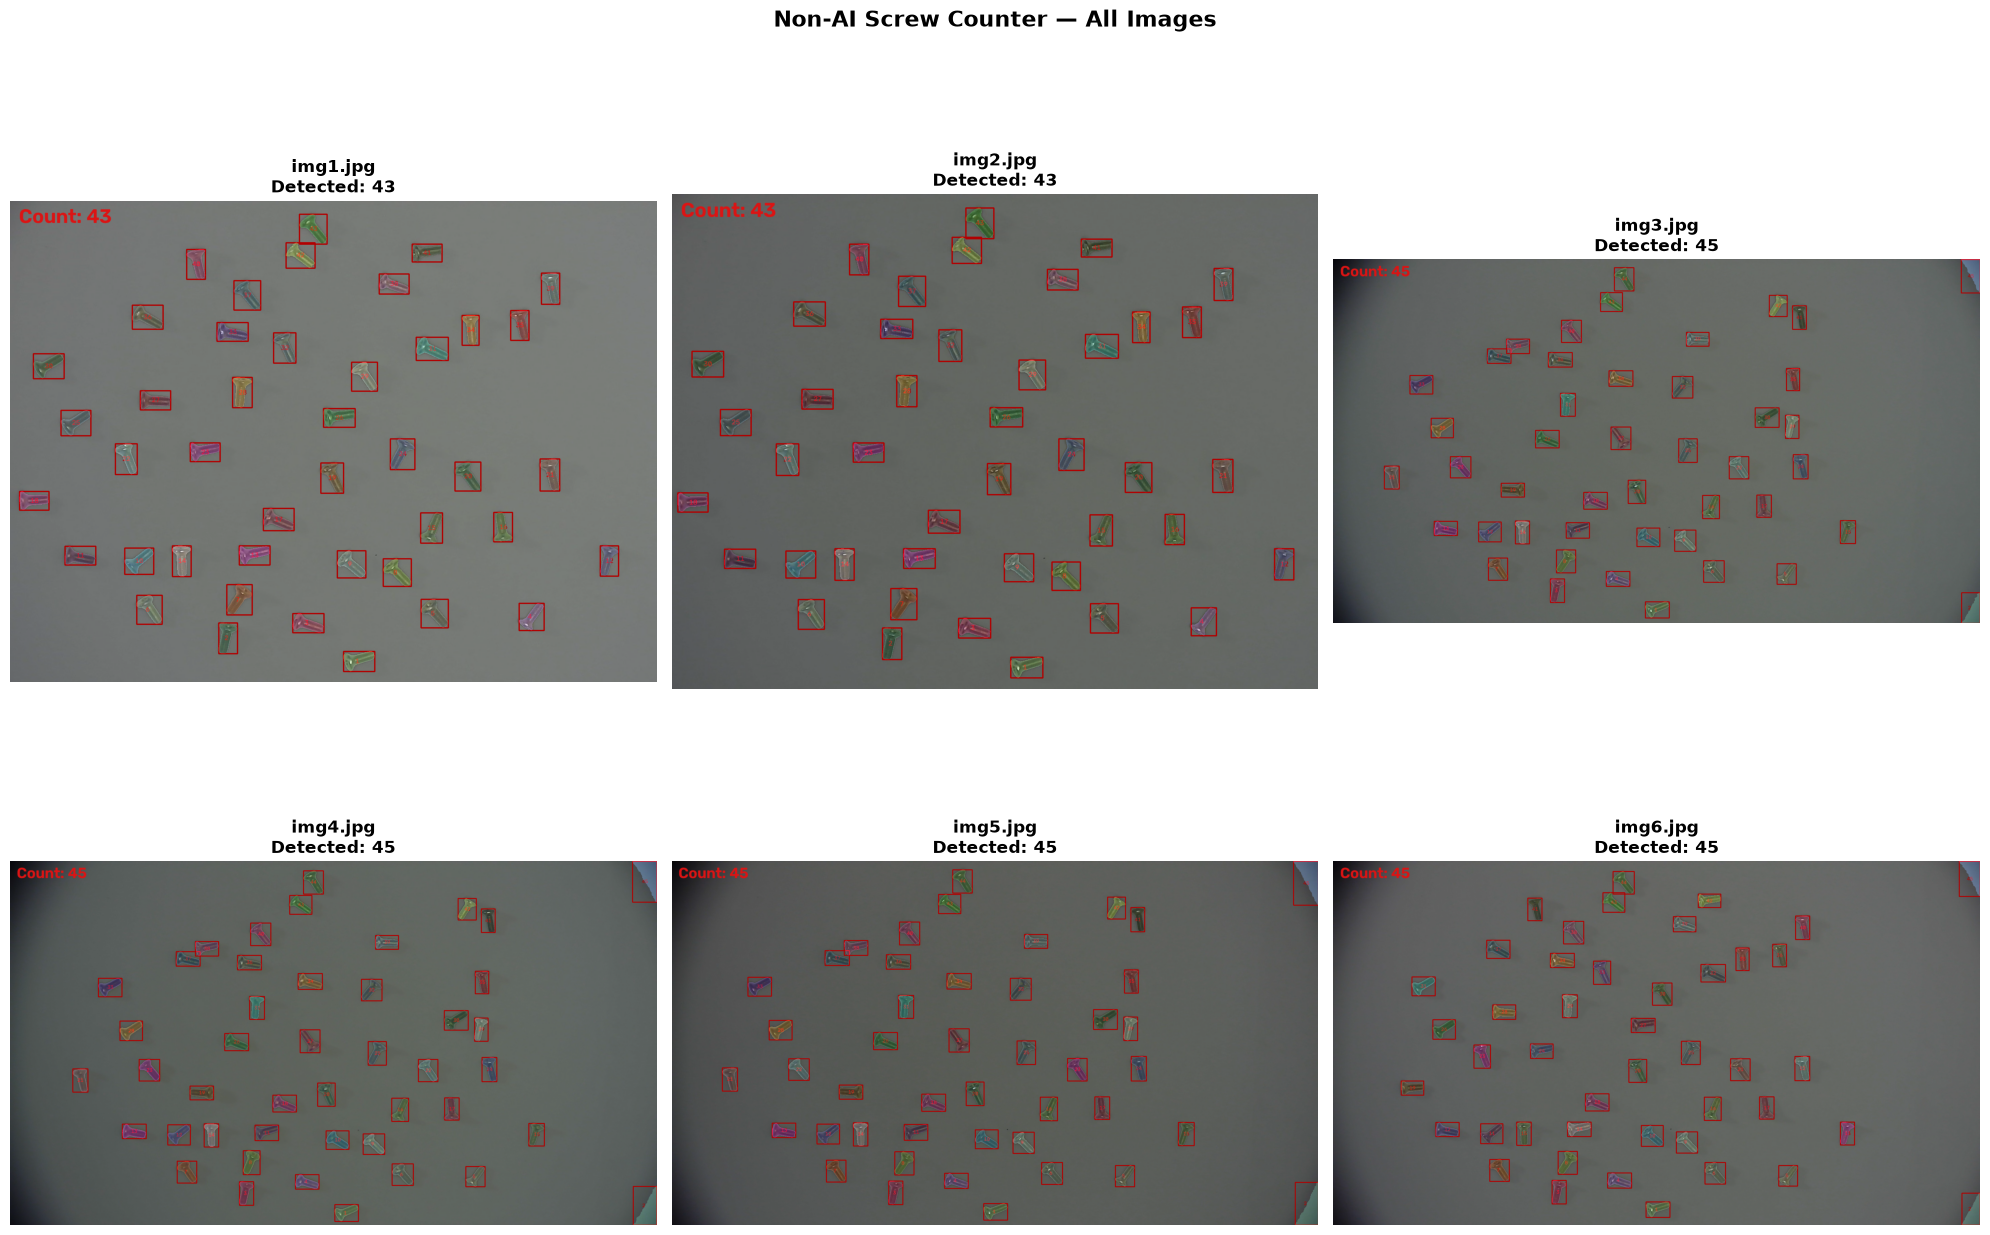


Summary:
  img1.jpg: 43 screws
  img2.jpg: 43 screws
  img3.jpg: 45 screws
  img4.jpg: 45 screws
  img5.jpg: 45 screws
  img6.jpg: 45 screws


In [5]:
# --- Run all images, show results side by side ---
results = {}

n = len(image_files)
cols = 3
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(20, rows * 7))
axes = axes.flatten()

for i, img_path in enumerate(image_files):
    count, overlay, _ = count_screws(img_path)
    results[img_path.name] = count
    axes[i].imshow(overlay)
    axes[i].set_title(f'{img_path.name}\nDetected: {count}', fontsize=12, fontweight='bold')
    axes[i].axis('off')

# Hide unused axes
for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.suptitle('Non-AI Screw Counter — All Images', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('all_results_non_ai.png', dpi=120, bbox_inches='tight')
plt.show()

print('\nSummary:')
for name, cnt in results.items():
    print(f'  {name}: {cnt} screws')

In [ ]:
# --- Accuracy check ---
# Ground truth taken from the labeled reference images (img1_43_nosy.jpg → GT=43, etc.)
# All 6 images share similar GT counts because they're the same scene from slightly different angles

GROUND_TRUTH = {
    'img1.jpg': 43,
    'img2.jpg': 43,
    'img3.jpg': 45,
    'img4.jpg': 45,
    'img5.jpg': 45,
    'img6.jpg': 45,
}

print(f'{"Image":<15} {"GT":>5} {"Pred":>5} {"Accuracy":>10}')
print('-' * 40)

accs = []
for fname, gt in GROUND_TRUTH.items():
    pred = results.get(fname)
    if pred is not None:
        acc = (1 - abs(pred - gt) / gt) * 100
        accs.append(acc)
        flag = '' if acc >= 95 else '  <-- below 95%'
        print(f'{fname:<15} {gt:>5} {pred:>5} {acc:>9.1f}%{flag}')

print('-' * 40)
print(f'{"Average:":<15} {sum(accs)/len(accs):>21.1f}%')
print(f'Images >= 95%: {sum(1 for a in accs if a >= 95)} / {len(accs)}')

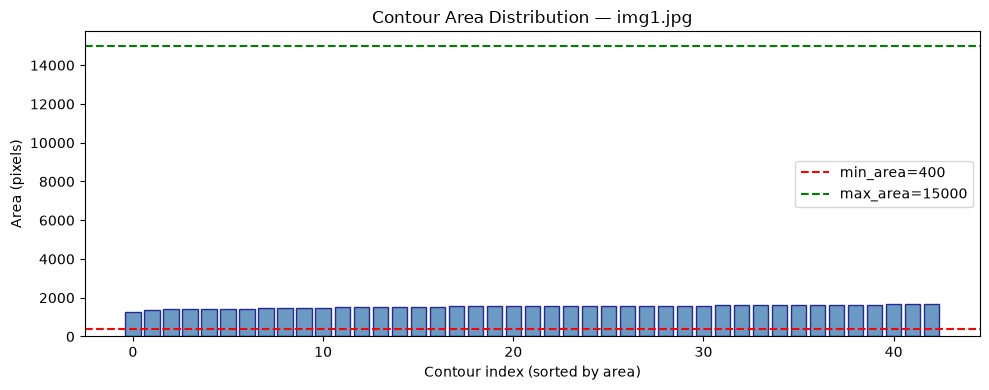

Total contours: 43 | Valid (400-15000): 43


In [7]:
# --- Area distribution plot: helps tune min_area / max_area ---
img_path = DATA_DIR / 'img1.jpg'
img = cv2.imread(str(img_path))
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
_, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
cleaned = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel, iterations=2)
cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_OPEN, kernel, iterations=1)
contours, _ = cv2.findContours(cleaned, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
areas = sorted([cv2.contourArea(c) for c in contours])

plt.figure(figsize=(10, 4))
plt.bar(range(len(areas)), areas, color='steelblue', edgecolor='navy', alpha=0.8)
plt.axhline(400, color='red', linestyle='--', label='min_area=400')
plt.axhline(15000, color='green', linestyle='--', label='max_area=15000')
plt.xlabel('Contour index (sorted by area)')
plt.ylabel('Area (pixels)')
plt.title('Contour Area Distribution — img1.jpg')
plt.legend()
plt.tight_layout()
plt.savefig('area_distribution.png', dpi=100, bbox_inches='tight')
plt.show()
print(f'Total contours: {len(areas)} | Valid (400-15000): {sum(1 for a in areas if 400 < a < 15000)}')